## Hướng dẫn chạy

Notebook chạy **độc lập từ trên xuống** (Run All), không phụ thuộc notebook khác.

**Cách dễ nhất — Kaggle:** tạo notebook mới bằng *File → Import Notebook* (chọn chính file `.ipynb` này) → bật **GPU (T4)** và **Internet** → Run All.

**Môi trường khác (Colab, Jupyter, Databricks...):**
- Python 3.10+, **PySpark ≥ 3.4** (cần cho `predict_batch_udf`), **Java 17+**, PyTorch, `transformers`.
- **Cần Internet**: tải mô hình `vinai/phobert-base-v2` từ Hugging Face và cài thư viện tách từ `pyvi` (ô cài đặt tự làm).
- **Nên có GPU.** Không có GPU, notebook tự bật `FAST_MODE` (1 epoch, 20% tập train, `max_len = 64`) để chạy xong trên CPU; kết quả khi đó thấp hơn.
- Dữ liệu được tự tìm theo thứ tự: thư mục `./data/` → `/kaggle/input/` (dataset `cthng123/absa-vietnamese`) → tự tải từ GitHub của nhóm (cần Internet).
- **Databricks:** dùng classic compute (cluster single-user/dedicated); Spark Connect / serverless không hỗ trợ `SparkContext.addFile`.
- Ô kiểm tra môi trường ở mục 3 khởi động thử Spark và dừng sớm với thông báo rõ ràng nếu thiếu Java, Java quá cũ hoặc Spark < 3.4.

**Thời gian chạy ước tính:** ~12–15 phút với GPU T4 (Kaggle); ~15 phút trên CPU 4 nhân (FAST_MODE).
Mô hình đóng gói bằng `pandas_udf`.

# NB3 — Phân loại bình luận theo khía cạnh bằng PhoBERT + đóng gói `pandas_udf`

**Nhóm 20** — Đinh Quang Nhật (24521248), Võ Tấn Nhã (24521225)

**Mục tiêu:** fine-tune mô hình ngôn ngữ tiếng Việt **PhoBERT** (`vinai/phobert-base-v2`) dự đoán cảm xúc cho
8 khía cạnh của bình luận giày trên Shopee, lưu mô hình, đóng gói thành UDF của Spark bằng **`pandas_udf`**,
áp dụng lên Spark DataFrame và đánh giá bằng `MulticlassClassificationEvaluator` của Spark.

| Khía cạnh | Price, Shipping, Outlook, Quality, Size, Shop_Service, General, Others |
|---|---|
| Nhãn | None (không nhắc đến), Negative, Positive, Neutral |

## 1. Cài đặt & import

In [1]:
# Cài các gói còn thiếu. KHÔNG cài đè pyspark/torch để giữ nguyên môi trường Spark sẵn có.
# pyvi: tách từ tiếng Việt (PhoBERT cần văn bản đã tách từ); transformers: tải và chạy PhoBERT.
import importlib.util
import subprocess
import sys

for pkg, module in [("pandas", "pandas"), ("pyarrow", "pyarrow"), ("scikit-learn", "sklearn"),
                    ("matplotlib", "matplotlib"), ("transformers", "transformers"), ("pyvi", "pyvi")]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

for module in ["torch", "pyspark"]:
    if importlib.util.find_spec(module) is None:
        raise ImportError(f"Thiếu thư viện {module}. Hãy chạy trong môi trường có sẵn {module} (Kaggle, Colab...).")

import time

import matplotlib.pyplot as plt

## 2. Code dùng chung

Khối dưới đây giống hệt nhau ở cả 5 notebook (nguồn: `common/common_cells.py` trong repo của nhóm):
hằng số, kiểm tra môi trường, đọc/chia dữ liệu, vòng lặp huấn luyện `fit`, các hàm Spark
(`create_spark`, `to_spark_df`, `explode_predictions`, `evaluate_with_spark`, `ship_model_to_spark`).

**Mã hóa nhãn nội bộ:** `0 = None, 1 = Negative, 2 = Positive, 3 = Neutral` (= nhãn gốc + 1 với Neutral 2 → 3),
vì evaluator của Spark cần nhãn không âm.

In [2]:
# === COMMON common_cells.py v2 ===
# Khối code dùng chung cho cả 5 notebook — dán NGUYÊN VĂN file common/common_cells.py vào ô này.
# Gồm: hằng số, kiểm tra môi trường, đọc/chia dữ liệu, vòng lặp huấn luyện, tiện ích Spark.
import copy
import glob
import os
import random
import re
import shutil
import subprocess
import sys
import tempfile
import time
import unicodedata
import urllib.request
import uuid

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as TF  # không đặt tên F: notebook Spark hay dùng F = pyspark.sql.functions
from sklearn.metrics import f1_score

COMMON_VERSION = 2

# ---------------------------------------------------------------------------
# 1. Hằng số
# ---------------------------------------------------------------------------
ASPECTS = ["Price", "Shipping", "Outlook", "Quality", "Size", "Shop_Service", "General", "Others"]
LABEL_NAMES = ["None", "Negative", "Positive", "Neutral"]  # nhãn nội bộ 0..3
ORIG_TO_IDX = {-1: 0, 0: 1, 1: 2, 2: 3}                    # nhãn gốc của dataset → nhãn nội bộ
SEED = 42

DATASET_REF = "cthng123/absa-vietnamese"
DATA_FILES = ("train_data.csv", "val_data.csv", "test_data.csv")  # dataset có sẵn 3 tập
SPLIT_NAMES = ("train", "val", "test")
RAW_TEXT_COL = "Review"
RAW_ASPECT_COLS = {a: a for a in ASPECTS}  # tên cột gốc → tên trong ASPECTS (dataset dùng đúng tên)
# Bản sao dữ liệu trong repo GitHub (Public) — dùng khi chạy ngoài Kaggle
DATA_URL = "https://raw.githubusercontent.com/PeterBrr/absa-spark/main/data"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# Không có GPU → tự rút gọn cấu hình huấn luyện. Có thể gán lại thủ công: FAST_MODE = True/False
FAST_MODE = DEVICE == "cpu"


def set_seed(seed: int = SEED) -> None:
    """Cố định seed cho random, numpy, torch để kết quả lặp lại được."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# ---------------------------------------------------------------------------
# 2. Kiểm tra môi trường
# ---------------------------------------------------------------------------
def _version_tuple(v: str) -> tuple:
    return tuple(int(x) for x in re.findall(r"\d+", v)[:3])


def _java_version() -> str:
    java = "java"
    if os.environ.get("JAVA_HOME"):
        java = os.path.join(os.environ["JAVA_HOME"], "bin", "java")
    try:
        out = subprocess.run([java, "-version"], capture_output=True, text=True, timeout=30)
    except (OSError, subprocess.SubprocessError):  # không có java, hoặc java treo quá 30 giây
        return ""
    lines = (out.stderr or out.stdout).strip().splitlines()
    return lines[0] if lines else ""


def _java_major(version_line: str) -> int:
    """'openjdk version "21.0.13"' → 21; 'java version "1.8.0_392"' → 8; chuỗi rỗng → 0."""
    m = re.search(r'version "([^"]+)"', version_line) or re.search(r"(\d+(?:\.\d+)*)", version_line)
    if not m:
        return 0
    parts = [int(x) for x in re.findall(r"\d+", m.group(1))]
    if not parts:
        return 0
    return parts[1] if parts[0] == 1 and len(parts) > 1 else parts[0]


def check_environment(min_spark: str = "3.4", require_gpu: bool = False) -> dict:
    """Kiểm tra Python, PySpark, Java, GPU, rồi khởi động thử Spark.
    Dừng sớm (RuntimeError, thông báo tiếng Việt) nếu môi trường không chạy được — trước khi huấn luyện."""
    import pyspark

    info = {
        "python": sys.version.split()[0],
        "pyspark": pyspark.__version__,
        "java": _java_version(),
        "cuda": torch.cuda.is_available(),
        "fast_mode": FAST_MODE,
    }
    if _version_tuple(info["pyspark"]) < _version_tuple(min_spark):
        raise RuntimeError(
            f"PySpark {info['pyspark']} quá cũ: cần PySpark >= {min_spark} (predict_batch_udf có từ 3.4). "
            "Hãy dùng môi trường có Spark mới hơn (ví dụ Kaggle/Colab hiện tại có PySpark 4.x).")
    need_java = 17 if _version_tuple(info["pyspark"]) >= (4,) else 8
    if not info["java"]:
        raise RuntimeError(f"Không tìm thấy Java. PySpark {info['pyspark']} cần Java {need_java}+ — "
                           "hãy cài JDK hoặc đặt biến JAVA_HOME.")
    if _java_major(info["java"]) < need_java:
        raise RuntimeError(f"Java quá cũ ({info['java']}): PySpark {info['pyspark']} cần Java {need_java}+. "
                           "Hãy cài JDK mới hơn hoặc trỏ JAVA_HOME tới JDK mới.")
    try:  # khởi động thử Spark và chạy một job nhỏ
        create_spark().range(1).count()
    except Exception as exc:
        raise RuntimeError(f"Không khởi động được Spark ({type(exc).__name__}: {str(exc)[:300]}). "
                           "Kiểm tra lại Java/JAVA_HOME và bản cài PySpark.") from exc
    if not info["cuda"]:
        msg = ("Không có GPU: huấn luyện trên CPU. Notebook PhoBERT sẽ tự dùng cấu hình rút gọn (FAST_MODE) "
               "để chạy xong trong thời gian hợp lý; mô hình RNN không bị ảnh hưởng.")
        if require_gpu:
            raise RuntimeError(msg)
        print("CẢNH BÁO:", msg)
    for k, v in info.items():
        print(f"{k:>10}: {v}")
    return info


# ---------------------------------------------------------------------------
# 3. Dữ liệu
# ---------------------------------------------------------------------------
def _has_all_files(folder: str, files) -> bool:
    return all(os.path.isfile(os.path.join(folder, f)) for f in files)


def find_or_download_data(local_dir: str = "./data", kaggle_root: str = "/kaggle/input",
                          url: str = DATA_URL, files=DATA_FILES) -> str:
    """Trả về THƯ MỤC chứa 3 file dữ liệu. Tìm theo thứ tự:
    (1) local_dir, rồi ../data (khi notebook chạy từ thư mục notebooks/ của repo);
    (2) mọi thư mục con của /kaggle/input; (3) tải từ GitHub về local_dir."""
    for folder in (local_dir, os.path.join("..", "data")):
        if _has_all_files(folder, files):
            return folder
    for hit in sorted(glob.glob(os.path.join(kaggle_root, "**", files[0]), recursive=True)):
        folder = os.path.dirname(hit)
        if _has_all_files(folder, files):
            return folder
    os.makedirs(local_dir, exist_ok=True)
    downloaded = []
    try:
        for name in files:
            dest = os.path.join(local_dir, name)
            with urllib.request.urlopen(f"{url}/{name}", timeout=30) as resp, open(dest, "wb") as fh:
                fh.write(resp.read())
            downloaded.append(dest)
    except Exception as exc:  # không có mạng, repo Private, URL sai...
        for path in downloaded:
            os.remove(path)
        raise FileNotFoundError(
            f"Không tìm thấy dữ liệu {DATASET_REF} ({', '.join(files)}). Hãy làm MỘT trong các cách:\n"
            f"  1) Đặt 3 file vào thư mục {os.path.abspath(local_dir)}\n"
            f"  2) Trên Kaggle: Add Input → dataset '{DATASET_REF}'\n"
            f"  3) Bật Internet để tải tự động từ {url}\n"
            f"(Lỗi khi tải: {exc})") from exc
    print(f"Đã tải dữ liệu từ {url} về {local_dir}")
    return local_dir


_URL_RE = re.compile(r"https?://\S+|www\.\S+")
_REPEAT_RE = re.compile(r"([^\W\d_])\1{2,}")  # chữ cái lặp >= 3 lần ("đẹppppp" → "đẹp"); không đụng chữ số


def clean_text(text) -> str:
    """Tiền xử lý cơ bản: NFC, chữ thường, bỏ URL, rút gọn chữ cái lặp, gộp khoảng trắng."""
    if text is None or (isinstance(text, float) and np.isnan(text)):
        return ""
    text = unicodedata.normalize("NFC", str(text)).lower()
    text = _URL_RE.sub(" ", text)
    text = text.replace("￼", " ")  # ký tự "object replacement" hay gặp khi copy từ Shopee
    text = _REPEAT_RE.sub(r"\1", text)
    return re.sub(r"\s+", " ", text).strip()


def _read_raw(csv_path: str) -> pd.DataFrame:
    raw = pd.read_csv(csv_path)
    df = pd.DataFrame({"text": raw[RAW_TEXT_COL].map(clean_text)})
    for raw_col, aspect in RAW_ASPECT_COLS.items():
        mapped = raw[raw_col].map(ORIG_TO_IDX)
        if mapped.isna().any():
            bad = sorted(raw.loc[mapped.isna(), raw_col].unique().tolist())
            raise ValueError(f"Cột {raw_col} có nhãn lạ {bad}; chỉ chấp nhận {list(ORIG_TO_IDX)}")
        df[aspect] = mapped.astype("int64")
    return df[["text", *ASPECTS]]


def load_dataset(path: str) -> pd.DataFrame:
    """Đọc dữ liệu → cột ["text", *ASPECTS] (nhãn nội bộ 0..3).
    `path` là thư mục chứa 3 file (thêm cột "split") hoặc một file CSV."""
    if os.path.isdir(path):
        parts = []
        for name, split in zip(DATA_FILES, SPLIT_NAMES):
            part = _read_raw(os.path.join(path, name))
            part["split"] = split
            parts.append(part)
        return pd.concat(parts, ignore_index=True)
    return _read_raw(path)


def get_splits(df: pd.DataFrame, seed: int = SEED):
    """Trả về (train, val, test). Dùng cột "split" nếu có, ngược lại chia ngẫu nhiên 80/10/10."""
    if "split" in df.columns:
        return tuple(df[df["split"] == s].drop(columns="split") for s in SPLIT_NAMES)
    order = np.random.RandomState(seed).permutation(len(df))
    n_train, n_val = int(0.8 * len(df)), int(0.1 * len(df))
    idx = (order[:n_train], order[n_train:n_train + n_val], order[n_train + n_val:])
    return tuple(df.iloc[np.sort(i)] for i in idx)


def resolve_train_config(base: dict, fast: bool = None) -> dict:
    """Trả về bản sao cấu hình; khi fast (mặc định = FAST_MODE) thì rút gọn để chạy được trên CPU."""
    cfg = dict(base)
    fast = FAST_MODE if fast is None else fast
    if fast:
        cfg["epochs"] = 1
        cfg["max_len"] = min(cfg.get("max_len", 64), 64)
        cfg["train_frac"] = min(cfg.get("train_frac", 1.0), 0.2)
        print("FAST_MODE: dùng cấu hình rút gọn", cfg)
    return cfg


# ---------------------------------------------------------------------------
# 4. Huấn luyện
# ---------------------------------------------------------------------------
def ce_loss(logits, labels):
    """CrossEntropy trung bình trên 8 khía cạnh. logits [B,8,4], labels [B,8]."""
    return TF.cross_entropy(logits.reshape(-1, logits.shape[-1]), labels.reshape(-1))


def argmax_labels(out):
    """Chuyển logits [B,8,4] → nhãn [B,8]."""
    return out.argmax(dim=-1)


def macro_f1_mean(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """Trung bình theo khía cạnh của macro-F1; mỗi khía cạnh chỉ tính trên các nhãn có mặt."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    scores = []
    for j in range(y_true.shape[1]):
        labels = sorted(set(y_true[:, j].tolist()) | set(y_pred[:, j].tolist()))
        scores.append(f1_score(y_true[:, j], y_pred[:, j], labels=labels, average="macro", zero_division=0))
    return float(np.mean(scores))


def _to_device(batch: dict, device):
    inputs = {k: v.to(device) for k, v in batch.items() if k != "labels"}
    labels = batch["labels"].to(device) if "labels" in batch else None
    return inputs, labels


def predict_labels(model, loader, to_labels=argmax_labels, device=None) -> np.ndarray:
    """Dự đoán nhãn [N,8] cho toàn bộ loader."""
    device = device or DEVICE
    model.to(device).eval()
    preds = []
    with torch.no_grad():
        for batch in loader:
            inputs, _ = _to_device(batch, device)
            preds.append(to_labels(model(**inputs)).cpu().numpy())
    return np.concatenate(preds) if preds else np.zeros((0, len(ASPECTS)), dtype=np.int64)


def fit(model, train_loader, val_loader, loss_fn=ce_loss, to_labels=argmax_labels,
        epochs: int = 3, lr: float = 2e-5, device=None, weight_decay: float = 0.01) -> dict:
    """Huấn luyện với AdamW; sau mỗi epoch đo macro-F1 trên val; cuối cùng nạp lại epoch tốt nhất.
    Mỗi batch là dict có khóa "labels"; các khóa còn lại được truyền vào model(**batch)."""
    device = device or DEVICE
    model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    y_val = np.concatenate([b["labels"].numpy() for b in val_loader])
    history = {"train_loss": [], "val_macro_f1": []}
    best_f1, best_state = -1.0, None
    for epoch in range(1, epochs + 1):
        start = time.time()
        model.train()
        total, n = 0.0, 0
        for batch in train_loader:
            inputs, labels = _to_device(batch, device)
            loss = loss_fn(model(**inputs), labels)
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total += loss.item() * len(labels)
            n += len(labels)
        val_f1 = macro_f1_mean(y_val, predict_labels(model, val_loader, to_labels, device))
        history["train_loss"].append(total / max(n, 1))
        history["val_macro_f1"].append(val_f1)
        if val_f1 > best_f1:
            best_f1, best_state = val_f1, copy.deepcopy(model.state_dict())
        print(f"Epoch {epoch}/{epochs} - loss {total / max(n, 1):.4f} - val macro-F1 {val_f1:.4f} "
              f"- {time.time() - start:.0f}s")
    if best_state is not None:
        model.load_state_dict(best_state)
    print(f"Nạp lại trọng số tốt nhất: val macro-F1 = {best_f1:.4f}")
    return history


# ---------------------------------------------------------------------------
# 5. Spark
# ---------------------------------------------------------------------------
from pyspark.sql import functions as SF  # noqa: E402  (đặt tên SF để không trùng tên F hay dùng trong notebook)
from pyspark.sql.types import IntegerType, StructField, StructType  # noqa: E402

# Kiểu trả về của UDF dự đoán: 8 trường số nguyên, tên theo ASPECTS
PRED_SCHEMA = StructType([StructField(a, IntegerType()) for a in ASPECTS])


def create_spark(app_name: str = "ABSA", master: str = "local[2]"):
    """Dùng lại SparkSession có sẵn (Databricks...) hoặc tạo session local.
    local[2]: mỗi worker Python nạp một bản mô hình, giới hạn 2 để không hết bộ nhớ GPU."""
    from pyspark.sql import SparkSession

    os.environ.setdefault("PYSPARK_PYTHON", sys.executable)
    os.environ.setdefault("PYSPARK_DRIVER_PYTHON", sys.executable)
    spark = (SparkSession.builder.appName(app_name).master(master)
             .config("spark.sql.execution.arrow.pyspark.enabled", "true")
             .getOrCreate())
    spark.conf.set("spark.sql.execution.arrow.pyspark.enabled", "true")
    if _version_tuple(spark.version) < (3, 4):
        raise RuntimeError(f"Spark {spark.version} quá cũ: cần Spark >= 3.4 cho predict_batch_udf.")
    return spark


def to_spark_df(spark, df: pd.DataFrame):
    """pandas → Spark DataFrame: id (long), text (string), 8 cột nhãn (double, cho evaluator)."""
    pdf = df[["text", *ASPECTS]].reset_index(drop=True).copy()
    pdf.insert(0, "id", np.arange(len(pdf), dtype="int64"))
    pdf["text"] = pdf["text"].fillna("").astype(str)
    pdf[ASPECTS] = pdf[ASPECTS].astype("float64")
    return spark.createDataFrame(pdf)


def explode_predictions(sdf, struct_col: str = "pred"):
    """Tách cột struct dự đoán thành 8 cột pred_<aspect> kiểu double."""
    for a in ASPECTS:
        sdf = sdf.withColumn(f"pred_{a}", SF.col(f"{struct_col}.{a}").cast("double"))
    return sdf


def evaluate_with_spark(sdf) -> pd.DataFrame:
    """Đánh giá từng khía cạnh bằng MulticlassClassificationEvaluator.
    Cần cột nhãn <aspect> và cột dự đoán pred_<aspect> (double).
    Trả về bảng: accuracy, f1_weighted, f1_macro + dòng Mean.
    f1_macro = trung bình F1 trên các nhãn có mặt (trong nhãn thật hoặc dự đoán), giống
    sklearn f1_score(average="macro", zero_division=0)."""
    from pyspark.ml.evaluation import MulticlassClassificationEvaluator

    cached_here = False
    try:  # cache để 8 lần đánh giá không tính lại UDF; một số môi trường (serverless) không cho cache
        if not sdf.is_cached:
            sdf, cached_here = sdf.cache(), True
    except Exception:
        pass
    rows = {}
    for a in ASPECTS:
        ev = MulticlassClassificationEvaluator(labelCol=a, predictionCol=f"pred_{a}")
        true_labels = {r[0] for r in sdf.select(a).distinct().collect()}
        pred_labels = {r[0] for r in sdf.select(f"pred_{a}").distinct().collect()}
        # Spark chỉ tính fMeasureByLabel cho nhãn có trong nhãn thật (nhãn chỉ có trong dự đoán sẽ lỗi
        # "key not found"); nhãn đó không có mẫu đúng nào nên F1 = 0.
        f1_by_label = [ev.evaluate(sdf, {ev.metricName: "fMeasureByLabel", ev.metricLabel: float(k)})
                       for k in sorted(true_labels)]
        f1_by_label += [0.0] * len(pred_labels - true_labels)
        rows[a] = {
            "accuracy": ev.evaluate(sdf, {ev.metricName: "accuracy"}),
            "f1_weighted": ev.evaluate(sdf, {ev.metricName: "f1"}),
            "f1_macro": float(np.mean(f1_by_label)),
        }
    if cached_here:
        sdf.unpersist()
    result = pd.DataFrame.from_dict(rows, orient="index")[["accuracy", "f1_weighted", "f1_macro"]]
    result.loc["Mean"] = result.mean()
    return result


_IS_WINDOWS = os.name == "nt"


def _is_spark_connect(spark) -> bool:
    return type(spark).__module__.startswith("pyspark.sql.connect")


def ship_model_to_spark(spark, model_dir: str) -> str:
    """Gửi thư mục mô hình tới mọi executor (chạy được cả local lẫn cluster).
    Chép sang thư mục tên duy nhất để chạy lại notebook không bị lỗi "file already added".
    Trả về "tên" để dùng trong UDF qua shipped_model_path(<tên>).

    - Mặc định (Kaggle, Colab, Databricks classic, YARN...): SparkContext.addFile gửi bản chép tới
      từng executor; UDF lấy đường dẫn bằng SparkFiles.get.
    - Ngoại lệ duy nhất: Jupyter trên Windows ở local mode. Hadoop trên Windows cần winutils; thiếu nó,
      một lần addFile lỗi làm MỌI job Spark sau đó thất bại. Vì driver và worker cùng một máy,
      worker đọc thẳng bản chép qua đường dẫn tuyệt đối.
    - Spark Connect (vd Databricks serverless) không có SparkContext → báo lỗi rõ ràng."""
    if _is_spark_connect(spark):
        raise RuntimeError(
            "Phiên Spark Connect (vd Databricks serverless / Free Edition) không hỗ trợ SparkContext.addFile "
            "để gửi mô hình tới executor. Hãy chạy notebook trên classic compute (Databricks: cluster "
            "single-user/dedicated), Kaggle, Colab hoặc Jupyter có PySpark.")
    base = os.path.basename(os.path.normpath(model_dir))
    name = f"{base}_{time.strftime('%Y%m%d_%H%M%S')}_{uuid.uuid4().hex[:6]}"
    dest = os.path.join(tempfile.gettempdir(), "absa_ship", name)
    shutil.copytree(model_dir, dest)
    if _IS_WINDOWS and spark.sparkContext.master.startswith("local"):
        print("Windows + local mode: worker đọc mô hình trực tiếp từ thư mục tạm", name)
        return dest
    spark.sparkContext.addFile(dest, recursive=True)
    return name


def shipped_model_path(shipped_name: str) -> str:
    """Dùng BÊN TRONG UDF: trả về thư mục mô hình trên worker (từ SparkFiles, hoặc đường dẫn cục bộ
    trong trường hợp Windows + local mode của ship_model_to_spark)."""
    from pyspark import SparkFiles

    if os.path.isabs(shipped_name) and os.path.isdir(shipped_name):
        return shipped_name
    return SparkFiles.get(shipped_name)

## 3. Kiểm tra môi trường

In [3]:
info = check_environment()  # dừng sớm nếu thiếu Java hoặc Spark < 3.4
set_seed(SEED)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/16 03:23:17 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


    python: 3.13.16
   pyspark: 4.0.4
      java: openjdk version "21.0.12.1" 2026-08-18
      cuda: True
 fast_mode: False


## 4. Đọc & khám phá dữ liệu

Dataset có sẵn 3 tập train / val / test. `load_dataset` đọc cả 3, làm sạch văn bản và đổi nhãn sang mã nội bộ.

In [4]:
data_dir = find_or_download_data()
df = load_dataset(data_dir)
train_df, val_df, test_df = get_splits(df)
print(f"train = {len(train_df)}, val = {len(val_df)}, test = {len(test_df)}")
df.head()

train = 8424, val = 936, test = 2340


,text,Price,Shipping,Outlook,Quality,Size,Shop_Service,General,Others,split
0,"giày đẹp, đi êm lắm",0,0,2,2,0,0,0,0,train
1,mình săn sale với giá khá rẻ chất lượng ok shi...,2,2,0,2,0,0,0,0,train
2,hình ảnh và video chỉ mang tính chất minh họa ...,2,2,0,0,0,0,2,0,train
3,mình đặt size 39 nhưng chật k đeo nổi. còn giầ...,0,2,2,0,1,0,0,0,train
4,nên mua nha mọi người đẹp xuất sắc lun ạ,0,0,2,0,0,0,0,0,train


,None,Negative,Positive,Neutral
Price,9970,16,1282,432
Shipping,8174,564,2782,180
Outlook,5361,459,5579,301
Quality,8213,463,2467,557
Size,9725,662,842,471
Shop_Service,8641,687,2216,156
General,9389,73,1372,866
Others,10764,0,0,936


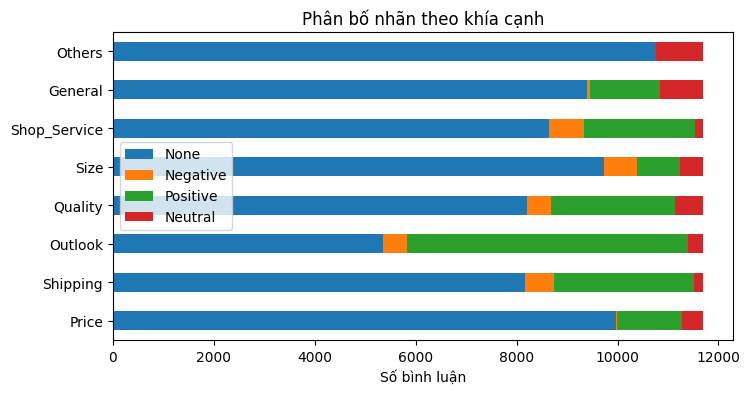

In [5]:
# Phân bố nhãn theo từng khía cạnh: phần lớn là None (khía cạnh không được nhắc đến) → dữ liệu lệch
dist = pd.DataFrame({a: df[a].value_counts().reindex(range(4), fill_value=0) for a in ASPECTS}).T
dist.columns = LABEL_NAMES
display(dist)
dist.plot(kind="barh", stacked=True, figsize=(8, 4), title="Phân bố nhãn theo khía cạnh")
plt.xlabel("Số bình luận")
plt.show()

count    11700.000000
mean        20.727778
std         20.700081
min          1.000000
25%         12.000000
50%         17.000000
75%         24.000000
max        692.000000
Name: text, dtype: float64
Phân vị 95% số âm tiết: 46


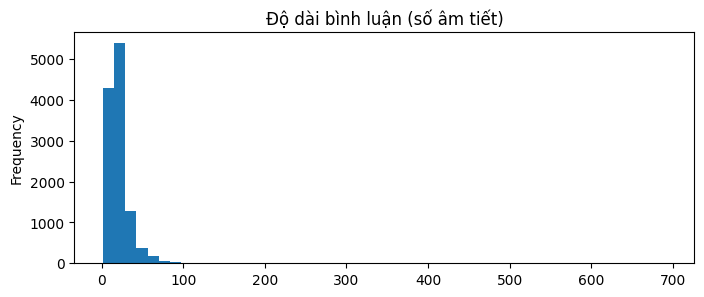

In [6]:
# Độ dài bình luận (số âm tiết). PhoBERT dùng max_len = 128 token con (subword) — đủ cho hầu hết câu;
# tỉ lệ câu bị cắt được kiểm tra lại sau khi tách từ + tokenize ở mục 6.
lengths = df["text"].str.split().str.len()
print(lengths.describe())
print("Phân vị 95% số âm tiết:", int(np.percentile(lengths, 95)))
lengths.plot(kind="hist", bins=50, figsize=(8, 3), title="Độ dài bình luận (số âm tiết)")
plt.show()

## 5. Tiền xử lý

`clean_text` (trong khối code chung) đã được áp dụng khi đọc dữ liệu: chuẩn hóa Unicode NFC, chữ thường,
bỏ URL, rút gọn chữ cái lặp (`"đẹppppp"` → `"đẹp"`), gộp khoảng trắng.

**Tách từ cho PhoBERT:** PhoBERT được huấn luyện trên văn bản tiếng Việt **đã tách từ** (từ ghép nối bằng `_`,
vd `giao_hàng`), nên trước khi tokenize ta tách từ bằng `pyvi` (hàm `segment` trong khối PhoBERT ở mục 6).
Ví dụ minh họa dưới đây gọi `pyvi` trực tiếp.

In [7]:
from pyvi import ViTokenizer

for s in ["Giày ĐẸPPPPP lắm, giao hàngggg nhanh!!! https://shopee.vn/abc", "Size   39 chật quá 😭"]:
    cleaned = clean_text(s)
    print(repr(s), "→", repr(cleaned), "→", repr(ViTokenizer.tokenize(cleaned)))

'Giày ĐẸPPPPP lắm, giao hàngggg nhanh!!! https://shopee.vn/abc' → 'giày đẹp lắm, giao hàng nhanh!!!' → 'giày đẹp lắm , giao hàng nhanh ! ! !'
'Size   39 chật quá 😭' → 'size 39 chật quá 😭' → 'size 39 chật quá 😭'


## 6. Xây dựng mô hình PhoBERT

Khối code PhoBERT (nguồn: `common/bert_cells.py`, dùng chung cho NB3, NB4, NB5):
- `segment`: `clean_text` → tách từ bằng `pyvi`.
- `PhoBertAbsa`: encoder PhoBERT → **pooling** → **8 đầu phân loại** (mỗi khía cạnh một đầu, 4 lớp).
  Notebook này dùng pooling `"cls"` (vector của token đầu `<s>`); NB5 so sánh thêm `mean`, `max`, `attention`.
- `make_bert_loaders`: tokenize văn bản đã tách từ, đệm động theo từng batch.
- `save_bert` / `load_bert_predictor`: lưu trọng số + cấu hình encoder + tokenizer; khi nạp lại **không cần Internet**
  (quan trọng vì worker Spark có thể không truy cập được Hugging Face).

In [8]:
# === COMMON bert_cells.py v1 ===
# Mô hình PhoBERT cho ABSA — dán NGUYÊN VĂN file common/bert_cells.py vào ô này.
import json
import math
import os

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset

try:  # khi chạy pytest
    from common.common_cells import ASPECTS, clean_text
except ImportError:  # trong notebook: đã có sẵn từ ô code chung phía trên
    pass

MODEL_NAME = "vinai/phobert-base-v2"
POOLINGS = ("cls", "mean", "max", "attention")


def segment(texts) -> list:
    """Làm sạch (clean_text) rồi tách từ bằng pyvi, vd "Hàng hóa tốt" → "hàng_hóa tốt".
    PhoBERT được huấn luyện trên văn bản đã tách từ nên bước này là bắt buộc. Câu rỗng/None → ""."""
    from pyvi import ViTokenizer  # import trễ: chỉ cần khi thật sự tách từ (pip install pyvi)

    out = []
    for t in texts:
        t = clean_text(t)
        out.append(ViTokenizer.tokenize(t) if t else "")
    return out


class _AspectHeads(nn.Module):
    """8 đầu phân loại độc lập: mỗi khía cạnh một ma trận [H, C] riêng. Vào [B, 8, H] → ra [B, 8, C]."""

    def __init__(self, n_aspects: int, hidden: int, n_classes: int):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(n_aspects, hidden, n_classes) * 0.02)
        self.bias = nn.Parameter(torch.zeros(n_aspects, n_classes))

    def forward(self, feats):
        return torch.einsum("bah,ahc->bac", feats, self.weight) + self.bias


class PhoBertAbsa(nn.Module):
    """Encoder PhoBERT → pooling → 8 đầu phân loại (mỗi khía cạnh một đầu).

    pooling:
      - "cls": vector của token đầu <s>.
      - "mean" / "max": trung bình / lớn nhất trên các token thật (bỏ qua padding theo attention_mask).
      - "attention": MỖI KHÍA CẠNH MỘT VECTOR QUERY RIÊNG (8 query học được). Với khía cạnh a:
            k_t = tanh(W h_t),  α_{a,t} = softmax_t(q_a · k_t / √H)   (token padding bị loại),
            v_a = Σ_t α_{a,t} h_t
        → mỗi khía cạnh tự "nhìn" vào những từ liên quan tới nó (vd "giao", "ship" cho Shipping)
        thay vì dùng chung một vector câu như cls/mean/max.
    gated:
      - False → logits [B, 8, 4] (0=None, 1=Negative, 2=Positive, 3=Neutral).
      - True  → {"mention": [B, 8, 2] (có nhắc tới khía cạnh hay không),
                 "sentiment": [B, 8, 3] (Negative/Positive/Neutral)} — dùng với gated_loss.
    """

    def __init__(self, encoder: nn.Module, hidden_size: int, pooling: str = "cls", gated: bool = False,
                 n_aspects: int = 8, dropout: float = 0.1):
        super().__init__()
        if pooling not in POOLINGS:
            raise ValueError(f"pooling không hợp lệ: {pooling!r} (chọn {', '.join(POOLINGS)})")
        self.encoder, self.pooling, self.gated, self.n_aspects = encoder, pooling, gated, n_aspects
        self.dropout = nn.Dropout(dropout)
        if pooling == "attention":
            self.att_key = nn.Linear(hidden_size, hidden_size)
            self.att_query = nn.Parameter(torch.randn(n_aspects, hidden_size) * 0.02)
        if gated:
            self.mention_heads = _AspectHeads(n_aspects, hidden_size, 2)
            self.sentiment_heads = _AspectHeads(n_aspects, hidden_size, 3)
        else:
            self.heads = _AspectHeads(n_aspects, hidden_size, 4)

    def _pool(self, h, attention_mask):
        """h [B, L, H] → đặc trưng theo khía cạnh [B, 8, H]."""
        mask = attention_mask.unsqueeze(-1).to(h.dtype)                      # [B, L, 1]
        if self.pooling == "cls":
            v = h[:, 0]
        elif self.pooling == "mean":
            v = (h * mask).sum(1) / mask.sum(1).clamp(min=1.0)
        elif self.pooling == "max":
            v = h.masked_fill(mask == 0, torch.finfo(h.dtype).min).max(1).values
        else:  # attention: query riêng cho từng khía cạnh
            keys = torch.tanh(self.att_key(h))                                # [B, L, H]
            scores = torch.einsum("blh,ah->bal", keys, self.att_query) / math.sqrt(h.shape[-1])
            scores = scores.masked_fill(attention_mask.unsqueeze(1) == 0, torch.finfo(scores.dtype).min)
            return torch.einsum("bal,blh->bah", scores.softmax(-1), h)        # [B, 8, H]
        return v.unsqueeze(1).expand(-1, self.n_aspects, -1)                  # cùng vector cho 8 khía cạnh

    def forward(self, input_ids, attention_mask):
        h = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        feats = self.dropout(self._pool(h, attention_mask))
        if self.gated:
            return {"mention": self.mention_heads(feats), "sentiment": self.sentiment_heads(feats)}
        return self.heads(feats)


def gated_to_labels(out: dict):
    """Đầu ra gated → nhãn [B, 8]: không nhắc tới (mention = 0) → 0 (None); ngược lại sentiment + 1."""
    mentioned = out["mention"].argmax(-1)
    return torch.where(mentioned == 0, torch.zeros_like(mentioned), out["sentiment"].argmax(-1) + 1)


def build_phobert_absa(model_name: str = MODEL_NAME, pooling: str = "cls", gated: bool = False):
    """Tải PhoBERT (cần Internet lần đầu) → (PhoBertAbsa, tokenizer)."""
    from transformers import AutoModel, AutoTokenizer

    encoder = AutoModel.from_pretrained(model_name)
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    return PhoBertAbsa(encoder, encoder.config.hidden_size, pooling=pooling, gated=gated), tokenizer


class _BertDataset(Dataset):
    def __init__(self, df, tokenizer, max_len):
        enc = tokenizer(segment(df["text"].tolist()), truncation=True, max_length=max_len)
        self.input_ids = enc["input_ids"]
        self.labels = torch.tensor(df[ASPECTS].to_numpy(dtype=np.int64))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, i):
        return {"input_ids": self.input_ids[i], "labels": self.labels[i]}


def _bert_collate(pad_id: int):
    """Đệm động: mỗi batch chỉ đệm tới câu dài nhất trong batch (nhanh hơn đệm cố định max_len)."""
    def collate(items):
        width = max(len(x["input_ids"]) for x in items)
        ids = torch.full((len(items), width), pad_id, dtype=torch.long)
        mask = torch.zeros((len(items), width), dtype=torch.long)
        for i, x in enumerate(items):
            ids[i, :len(x["input_ids"])] = torch.tensor(x["input_ids"], dtype=torch.long)
            mask[i, :len(x["input_ids"])] = 1
        return {"input_ids": ids, "attention_mask": mask, "labels": torch.stack([x["labels"] for x in items])}
    return collate


def make_bert_loaders(train_df, val_df, tokenizer, max_len: int, batch_size: int = 16):
    """DataLoader cho train (xáo trộn) và val; batch {"input_ids", "attention_mask", "labels"}.
    Văn bản được tách từ (segment) trước khi đưa vào tokenizer."""
    collate = _bert_collate(tokenizer.pad_token_id)
    return (DataLoader(_BertDataset(train_df, tokenizer, max_len), batch_size=batch_size, shuffle=True,
                       collate_fn=collate),
            DataLoader(_BertDataset(val_df, tokenizer, max_len), batch_size=batch_size, shuffle=False,
                       collate_fn=collate))


def save_bert(model, tokenizer, cfg: dict, out_dir: str) -> None:
    """Lưu vào out_dir:
      - model.pt     : trọng số toàn mô hình (encoder + pooling + các đầu)
      - encoder/     : cấu hình kiến trúc encoder (để dựng lại KHÔNG cần tải từ Internet)
      - tokenizer/   : tokenizer
      - config.json  : cfg (pooling, gated, max_len, model_name) + hidden_size"""
    os.makedirs(out_dir, exist_ok=True)
    torch.save(model.state_dict(), os.path.join(out_dir, "model.pt"))
    model.encoder.config.save_pretrained(os.path.join(out_dir, "encoder"))
    tokenizer.save_pretrained(os.path.join(out_dir, "tokenizer"))
    meta = {**cfg, "pooling": model.pooling, "gated": model.gated,
            "hidden_size": model.encoder.config.hidden_size}
    with open(os.path.join(out_dir, "config.json"), "w", encoding="utf-8") as fh:
        json.dump(meta, fh, ensure_ascii=False, indent=2)


def load_bert_predictor(model_dir: str, batch_size: int = 32):
    """Nạp mô hình đã lưu (không cần Internet) → predictor(list[str]) -> np.ndarray (N, 8) nhãn 0..3."""
    from transformers import AutoConfig, AutoModel, AutoTokenizer

    with open(os.path.join(model_dir, "config.json"), encoding="utf-8") as fh:
        cfg = json.load(fh)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    encoder = AutoModel.from_config(AutoConfig.from_pretrained(os.path.join(model_dir, "encoder")))
    tokenizer = AutoTokenizer.from_pretrained(os.path.join(model_dir, "tokenizer"))
    model = PhoBertAbsa(encoder, cfg["hidden_size"], pooling=cfg["pooling"], gated=cfg["gated"])
    model.load_state_dict(torch.load(os.path.join(model_dir, "model.pt"), map_location=device))
    model.to(device).eval()
    to_labels = gated_to_labels if cfg["gated"] else (lambda out: out.argmax(-1))
    max_len = cfg["max_len"]

    def predictor(texts) -> np.ndarray:
        preds = [np.zeros((0, len(ASPECTS)), dtype=np.int64)]
        with torch.no_grad():
            for i in range(0, len(texts), batch_size):
                enc = tokenizer(segment(texts[i:i + batch_size]), truncation=True, max_length=max_len,
                                padding=True, return_tensors="pt")
                out = model(enc["input_ids"].to(device), enc["attention_mask"].to(device))
                preds.append(to_labels(out).cpu().numpy())
        return np.concatenate(preds)

    return predictor

In [9]:
# 5 epoch: thử với 3 epoch thì val macro-F1 vẫn còn tăng mạnh ở epoch cuối (0,50 → 0,58 → 0,63)
cfg = resolve_train_config({"epochs": 5, "max_len": 128, "batch_size": 16, "lr": 2e-5, "train_frac": 1.0,
                            "pooling": "cls", "gated": False, "model_name": MODEL_NAME})
train_fit = train_df.sample(frac=cfg["train_frac"], random_state=SEED)

model, tokenizer = build_phobert_absa(cfg["model_name"], pooling=cfg["pooling"], gated=cfg["gated"])
train_loader, val_loader = make_bert_loaders(train_fit, val_df, tokenizer, cfg["max_len"], cfg["batch_size"])

# Tỉ lệ câu dài hơn max_len token (bị cắt bớt) sau khi tách từ + tokenize
n_tok = np.array([len(ids) for ids in train_loader.dataset.input_ids])
print(f"train = {len(train_fit)} câu — số token: trung vị {int(np.median(n_tok))}, "
      f"phân vị 95% {int(np.percentile(n_tok, 95))}; bị cắt ở {cfg['max_len']}: {(n_tok >= cfg['max_len']).mean():.1%}")
print(f"Số tham số: {sum(p.numel() for p in model.parameters()):,}")

config.json:   0%|          | 0.00/678 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  540MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  540MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: vinai/phobert-base-v2
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

train = 8424 câu — số token: trung vị 20, phân vị 95% 53; bị cắt ở 128: 0.6%
Số tham số: 135,022,880


## 7. Huấn luyện (fine-tune)

Loss = trung bình CrossEntropy của 8 khía cạnh; tối ưu AdamW với `lr = 2e-5` (mức thường dùng khi fine-tune BERT),
cập nhật **toàn bộ** PhoBERT cùng các đầu phân loại. Sau mỗi epoch đo **macro-F1 trung bình 8 khía cạnh** trên tập val;
cuối cùng giữ lại trọng số của epoch tốt nhất.

Epoch 1/5 - loss 0.6053 - val macro-F1 0.5021 - 118s
Epoch 2/5 - loss 0.3756 - val macro-F1 0.5810 - 122s
Epoch 3/5 - loss 0.2969 - val macro-F1 0.6286 - 123s
Epoch 4/5 - loss 0.2471 - val macro-F1 0.6596 - 122s
Epoch 5/5 - loss 0.2094 - val macro-F1 0.6485 - 122s
Nạp lại trọng số tốt nhất: val macro-F1 = 0.6596
Thời gian huấn luyện: 10.1 phút


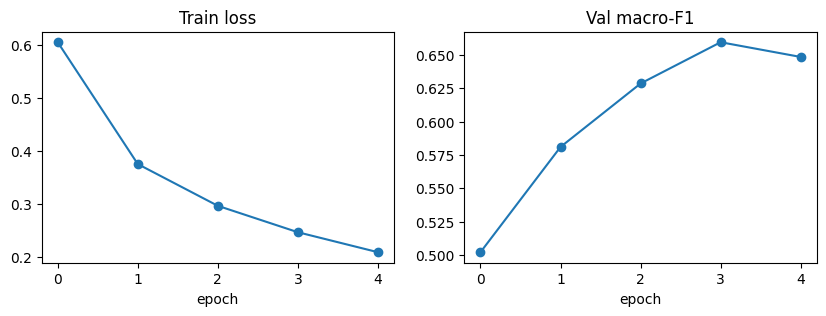

In [10]:
start = time.time()
history = fit(model, train_loader, val_loader, epochs=cfg["epochs"], lr=cfg["lr"])
print(f"Thời gian huấn luyện: {(time.time() - start) / 60:.1f} phút")

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(history["train_loss"], marker="o"); ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch")
ax[1].plot(history["val_macro_f1"], marker="o"); ax[1].set_title("Val macro-F1"); ax[1].set_xlabel("epoch")
plt.show()

## 8. Lưu mô hình

Lưu vào `./models/phobert/`: trọng số (`model.pt`), cấu hình kiến trúc encoder (`encoder/`), tokenizer (`tokenizer/`)
và cấu hình huấn luyện (`config.json`: pooling, max_len...). Sau đó giải phóng mô hình khỏi GPU để nhường bộ nhớ
cho các worker Spark ở mục 9.

In [11]:
MODEL_DIR = "./models/phobert"
save_bert(model, tokenizer, cfg, MODEL_DIR)
print(sorted(os.listdir(MODEL_DIR)))

del model, train_loader, val_loader
if torch.cuda.is_available():
    torch.cuda.empty_cache()

['config.json', 'encoder', 'model.pt', 'tokenizer']


## 9. Đóng gói mô hình bằng `pandas_udf`

1. `create_spark(master="local[2]")` dùng lại SparkSession có sẵn hoặc tạo session local **2 luồng**.
2. `ship_model_to_spark` gửi thư mục mô hình tới mọi executor (`SparkContext.addFile`); trong UDF lấy đường dẫn
   bằng `shipped_model_path` → `SparkFiles.get` — chạy được cả khi Spark chạy trên cluster nhiều máy.
3. `make_pandas_udf` (nguồn: `common/udf_pandas.py`) tạo **pandas_udf dạng Iterator**: mô hình được nạp **một lần
   cho mỗi partition** rồi dùng lại cho mọi batch, thay vì nạp lại ở từng batch. Bên trong, `load_bert_predictor`
   chia tiếp thành batch 32 câu khi chạy PhoBERT. UDF trả về một cột struct gồm 8 nhãn.

In [12]:
# local[2]: mỗi luồng Spark chạy một worker Python, và MỖI worker nạp một bản PhoBERT riêng lên GPU
# (~0,6 GB trọng số + bộ nhớ tính toán). Giới hạn 2 worker để không hết bộ nhớ GPU (T4 16 GB);
# dùng local[*] trên máy nhiều nhân sẽ nạp nhiều bản mô hình cùng lúc.
spark = create_spark(master="local[2]")
shipped = ship_model_to_spark(spark, MODEL_DIR)
print(spark.version, os.path.basename(shipped))

4.0.4 phobert_20261116_033402_dd2a4f


In [13]:
# === COMMON udf_pandas.py v1 ===
# Đóng gói mô hình bằng pandas_udf — dán NGUYÊN VĂN file common/udf_pandas.py vào ô này.
from typing import Callable, Iterator

import numpy as np
import pandas as pd
from pyspark.sql.functions import pandas_udf

try:  # khi chạy pytest
    from common.common_cells import ASPECTS, PRED_SCHEMA, shipped_model_path
except ImportError:  # trong notebook: đã có sẵn từ ô code chung phía trên
    pass


def make_pandas_udf(load_predictor: Callable[[str], Callable], shipped_name: str):
    """Tạo pandas_udf dự đoán 8 nhãn cho cột văn bản.

    - load_predictor(model_dir) -> predictor(list[str]) -> np.ndarray (N, 8), nhãn 0..3.
    - shipped_name: tên trả về từ ship_model_to_spark(); mô hình được gửi tới từng worker,
      vì thư mục mô hình gốc chỉ có trên máy driver — cách này chạy được cả trên cluster nhiều máy
      (shipped_model_path lấy đường dẫn qua SparkFiles.get).

    Dùng dạng Iterator[pd.Series] -> Iterator[pd.DataFrame]: mô hình được nạp MỘT LẦN cho mỗi
    partition (trước vòng lặp), rồi dùng lại cho mọi batch — tránh nạp lại mô hình ở từng batch.
    Kết quả là một cột struct (PRED_SCHEMA) gồm 8 trường; tách bằng explode_predictions().
    """

    @pandas_udf(PRED_SCHEMA)
    def predict_udf(batches: Iterator[pd.Series]) -> Iterator[pd.DataFrame]:
        predictor = load_predictor(shipped_model_path(shipped_name))  # nạp 1 lần / partition
        for texts in batches:
            # Văn bản rỗng/None vẫn được dự đoán (thường ra None cho cả 8 khía cạnh)
            preds = np.asarray(predictor(texts.fillna("").astype(str).tolist()), dtype=np.int32)
            yield pd.DataFrame(preds, columns=ASPECTS)

    return predict_udf

In [14]:
bert_udf = make_pandas_udf(load_bert_predictor, shipped)

## 10. Áp dụng UDF lên Spark DataFrame

Tập test được đưa vào Spark DataFrame, gọi UDF trên cột `text`, rồi tách cột struct thành 8 cột `pred_<khía cạnh>`.

In [15]:
start = time.time()
test_sdf = to_spark_df(spark, test_df)
pred_sdf = explode_predictions(test_sdf.withColumn("pred", bert_udf("text"))).cache()
print(f"Dự đoán {pred_sdf.count()} bình luận qua Spark trong {time.time() - start:.0f} giây")
pred_sdf.select("text", *[f"pred_{a}" for a in ASPECTS]).show(5, truncate=40)

Dự đoán 2340 bình luận qua Spark trong 27 giây
+----------------------------------------+----------+-------------+------------+------------+---------+-----------------+------------+-----------+
|                                    text|pred_Price|pred_Shipping|pred_Outlook|pred_Quality|pred_Size|pred_Shop_Service|pred_General|pred_Others|
+----------------------------------------+----------+-------------+------------+------------+---------+-----------------+------------+-----------+
|giày hơi có mùi nồng, lưu ý đôi la kh...|       0.0|          0.0|         0.0|         0.0|      0.0|              0.0|         3.0|        0.0|
|hàng về đẹp lắm nha ship thân thiện đ...|       0.0|          2.0|         2.0|         0.0|      2.0|              0.0|         0.0|        0.0|
|             hàng ôk nên mua dày rất đẹp|       0.0|          0.0|         0.0|         0.0|      0.0|              0.0|         2.0|        0.0|
|bun. gti gửi oke sớ ơ đi sidbd. bởi đ...|       0.0|          0.0|    

## 11. Đánh giá bằng Spark evaluator

`evaluate_with_spark` dùng `MulticlassClassificationEvaluator` cho **từng khía cạnh**:
`accuracy`, `f1` (weighted) và macro-F1 (trung bình `fMeasureByLabel` trên các nhãn có mặt), kèm dòng trung bình.

In [16]:
result = evaluate_with_spark(pred_sdf)
display(result.round(4))

,accuracy,f1_weighted,f1_macro
Price,0.9453,0.9431,0.5933
Shipping,0.9632,0.9570,0.7003
Outlook,0.8983,0.8848,0.6071
Quality,0.8645,0.8545,0.6232
Size,0.9188,0.9077,0.6391
Shop_Service,0.9158,0.9100,0.6323
General,0.8744,0.8669,0.5409
Others,0.9748,0.9740,0.9101
Mean,0.9194,0.9122,0.6558


In [17]:
# Kiểm tra: mô hình phải tốt hơn cách đoán "None" cho mọi khía cạnh
baseline = macro_f1_mean(test_df[ASPECTS].values, np.zeros((len(test_df), 8), dtype=int))
print(f"Macro-F1 nếu luôn đoán None: {baseline:.4f} — mô hình: {result.loc['Mean', 'f1_macro']:.4f}")
assert list(result.index) == ASPECTS + ["Mean"]
assert result.loc["Mean", "f1_macro"] > baseline, "Mô hình không tốt hơn đoán toàn None"

Macro-F1 nếu luôn đoán None: 0.2426 — mô hình: 0.6558


## 12. Kết luận

Ô dưới đây tóm tắt kết quả **của chính lần chạy này** (lấy từ bảng đánh giá ở mục 11), nên luôn khớp với output.

**Nhận xét:**
- **Accuracy cao hơn hẳn macro-F1**, vì phần lớn khía cạnh trong mỗi bình luận là *None* (không được nhắc đến):
  đoán đúng None đã cho accuracy cao. Macro-F1 tính đều cho cả 4 nhãn nên phản ánh rõ hơn khả năng nhận ra
  Negative / Neutral — các nhãn ít dữ liệu và khó hơn.
- PhoBERT đã được huấn luyện trước trên lượng lớn văn bản tiếng Việt, còn BiLSTM (NB1/NB2) học từ đầu; ô dưới đây
  so sánh trực tiếp hai mô hình trên cùng tập test. PhoBERT cần đủ số epoch fine-tune: khi thử với 3 epoch, val
  macro-F1 vẫn còn tăng mạnh ở epoch cuối và kết quả test (0,626) chưa vượt BiLSTM (0,639), nên notebook dùng 5 epoch.
- Khi chạy ở `FAST_MODE` (không GPU) mô hình chỉ học 1 epoch trên 20% dữ liệu nên kết quả thấp hơn nhiều
  (thử trên CPU Kaggle: macro-F1 ≈ 0,31).
- Mô hình được đóng gói bằng **`pandas_udf`**, áp dụng lên Spark DataFrame
  và đánh giá bằng `MulticlassClassificationEvaluator`; mô hình được gửi tới executor bằng `addFile` / `SparkFiles`
  nên chạy được cả trên cluster nhiều máy.
- Hướng cải thiện: thử cách pooling khác thay cho CLS và các hàm loss xử lý mất cân bằng nhãn (NB5).

In [18]:
# Tóm tắt kết quả của lần chạy này
RNN_MACRO_F1 = 0.6390  # BiLSTM (NB1/NB2) trên cùng tập test — xem README của nhóm
per_aspect = result.drop(index="Mean")
best, worst = per_aspect["f1_macro"].idxmax(), per_aspect["f1_macro"].idxmin()
print(f"Cấu hình                        : {cfg['epochs']} epoch, max_len {cfg['max_len']}, "
      f"train_frac {cfg['train_frac']}, FAST_MODE = {FAST_MODE}")
print(f"Accuracy trung bình 8 khía cạnh : {result.loc['Mean', 'accuracy']:.4f}")
print(f"F1 (weighted) trung bình        : {result.loc['Mean', 'f1_weighted']:.4f}")
print(f"Macro-F1 trung bình             : {result.loc['Mean', 'f1_macro']:.4f}  "
      f"(đoán toàn None: {baseline:.4f}; BiLSTM NB1: {RNN_MACRO_F1:.4f})")
diff = result.loc["Mean", "f1_macro"] - RNN_MACRO_F1
print(f"So với BiLSTM                    : PhoBERT {'cao hơn' if diff > 0 else 'thấp hơn'} {abs(diff):.4f} macro-F1")
print(f"Khía cạnh tốt nhất (macro-F1)   : {best} = {per_aspect.loc[best, 'f1_macro']:.4f}")
print(f"Khía cạnh kém nhất (macro-F1)   : {worst} = {per_aspect.loc[worst, 'f1_macro']:.4f}")
print()
print("Số mẫu mỗi nhãn của khía cạnh kém nhất trên tập test:",
      {n: int(c) for n, c in zip(LABEL_NAMES, np.bincount(test_df[worst], minlength=4))})

Cấu hình                        : 5 epoch, max_len 128, train_frac 1.0, FAST_MODE = False
Accuracy trung bình 8 khía cạnh : 0.9194
F1 (weighted) trung bình        : 0.9122
Macro-F1 trung bình             : 0.6558  (đoán toàn None: 0.2426; BiLSTM NB1: 0.6390)
So với BiLSTM                    : PhoBERT cao hơn 0.0168 macro-F1
Khía cạnh tốt nhất (macro-F1)   : Others = 0.9101
Khía cạnh kém nhất (macro-F1)   : General = 0.5409

Số mẫu mỗi nhãn của khía cạnh kém nhất trên tập test: {'None': 1861, 'Negative': 11, 'Positive': 285, 'Neutral': 183}
